# ⚙️ 3. Feature Engineering - Création de Nouveaux Attributs

## Objectif
Créer de nouveaux attributs pour enrichir l'analyse et améliorer la performance des modèles.

## Plan de Feature Engineering
1. Ratios financiers
2. Indices comportementaux
3. Catégorisation des profils
4. Variables dérivées
5. Sélection des features


In [1]:
# Importation des bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
import warnings
import json
import os

warnings.filterwarnings('ignore')

# Configuration des graphiques
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# Configuration pour l'affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

print("📚 Bibliothèques importées avec succès!")


📚 Bibliothèques importées avec succès!


## 1. Chargement des données nettoyées


In [2]:
# Chargement des données nettoyées
df = pd.read_csv('../data/processed/dataset_cleaned.csv')

print(f"✅ Données chargées avec succès!")
print(f"📊 Dimensions: {df.shape[0]} lignes × {df.shape[1]} colonnes")
print(f"\n🔍 Colonnes disponibles:")
print(df.columns.tolist())


✅ Données chargées avec succès!
📊 Dimensions: 6000 lignes × 15 colonnes

🔍 Colonnes disponibles:
['ID', 'Age', 'Income (USD)', 'Rent (USD)', 'Groceries (USD)', 'Eating Out (USD)', 'Entertainment (USD)', 'Subscription Services (USD)', 'Education (USD)', 'Online Shopping (USD)', 'Savings (USD)', 'Investments (USD)', 'Travel (USD)', 'Fitness (USD)', 'Miscellaneous (USD)']


## 2. Création des Ratios Financiers

**⚠️ IMPORTANT**: Les ratios seront créés pour l'analyse, mais **NE SERONT PAS** inclus dans l'ACP et le clustering car ils biaisent les résultats.
Ils seront utilisés uniquement pour créer le target (Financial Profile) et pour l'interprétation.


In [3]:
# Création d'une copie pour le feature engineering
df_features = df.copy()

# Calcul des dépenses totales
df_features['Total_Expenses'] = (
    df_features['Rent (USD)'] + 
    df_features['Groceries (USD)'] + 
    df_features['Eating Out (USD)'] + 
    df_features['Entertainment (USD)'] + 
    df_features['Subscription Services (USD)'] + 
    df_features['Education (USD)'] + 
    df_features['Online Shopping (USD)'] + 
    df_features['Travel (USD)'] + 
    df_features['Fitness (USD)'] + 
    df_features['Miscellaneous (USD)']
)

# Calcul du revenu disponible
df_features['Disposable_Income'] = df_features['Income (USD)'] - df_features['Total_Expenses']

# Ratios financiers (⚠️ Ces ratios ne seront PAS utilisés dans ACP/Clustering)
# Taux d'épargne (% du revenu)
df_features['Savings_Rate'] = (df_features['Savings (USD)'] / df_features['Income (USD)']) * 100
df_features['Savings_Rate'] = df_features['Savings_Rate'].replace([np.inf, -np.inf], 0).fillna(0)

# Taux d'investissement (% du revenu)
df_features['Investment_Rate'] = (df_features['Investments (USD)'] / df_features['Income (USD)']) * 100
df_features['Investment_Rate'] = df_features['Investment_Rate'].replace([np.inf, -np.inf], 0).fillna(0)

# Taux de dépenses (% du revenu)
df_features['Expense_Rate'] = (df_features['Total_Expenses'] / df_features['Income (USD)']) * 100
df_features['Expense_Rate'] = df_features['Expense_Rate'].replace([np.inf, -np.inf], 0).fillna(0)

# Catégorisation du revenu
df_features['Income_Category'] = pd.cut(
    df_features['Income (USD)'],
    bins=[0, 3000, 5000, 7000, np.inf],
    labels=['Faible', 'Moyen', 'Eleve', 'Tres_Eleve']
)

print("✅ Ratios financiers créés!")
print(f"\n📊 Statistiques des ratios:")
print(df_features[['Savings_Rate', 'Investment_Rate', 'Expense_Rate']].describe())


✅ Ratios financiers créés!



📊 Statistiques des ratios:
       Savings_Rate  Investment_Rate  Expense_Rate
count   6000.000000      6000.000000   6000.000000
mean      17.057446         6.669956     84.391162
std       14.730341         6.131430     31.500712
min        0.000000         0.000000     27.813745
25%        0.000000         0.364278     62.799520
50%       17.026868         5.949605     77.771326
75%       29.485769        10.872204     99.482051
max       56.600021        42.390269    264.690772


## 3. Création des Indices Comportementaux

Ces indices aident à comprendre les comportements de dépenses.


In [4]:
# Indice de style de vie (dépenses de loisirs et divertissement)
df_features['Lifestyle_Index'] = (
    df_features['Eating Out (USD)'] + 
    df_features['Entertainment (USD)'] + 
    df_features['Travel (USD)']
) / df_features['Income (USD)'] * 100
df_features['Lifestyle_Index'] = df_features['Lifestyle_Index'].replace([np.inf, -np.inf], 0).fillna(0)

# Indice d'éducation (priorité à l'éducation)
df_features['Education_Index'] = (df_features['Education (USD)'] / df_features['Income (USD)']) * 100
df_features['Education_Index'] = df_features['Education_Index'].replace([np.inf, -np.inf], 0).fillna(0)

# Indice de santé (priorité à la santé et fitness)
df_features['Health_Index'] = (df_features['Fitness (USD)'] / df_features['Income (USD)']) * 100
df_features['Health_Index'] = df_features['Health_Index'].replace([np.inf, -np.inf], 0).fillna(0)

# Indice digital (abonnements et shopping en ligne)
df_features['Digital_Index'] = (
    df_features['Subscription Services (USD)'] + 
    df_features['Online Shopping (USD)']
) / df_features['Income (USD)'] * 100
df_features['Digital_Index'] = df_features['Digital_Index'].replace([np.inf, -np.inf], 0).fillna(0)

print("✅ Indices comportementaux créés!")
print(f"\n📊 Statistiques des indices:")
print(df_features[['Lifestyle_Index', 'Education_Index', 'Health_Index', 'Digital_Index']].describe())


✅ Indices comportementaux créés!

📊 Statistiques des indices:
       Lifestyle_Index  Education_Index  Health_Index  Digital_Index
count      6000.000000      6000.000000   6000.000000    6000.000000
mean         21.013369         8.981202      2.050270       9.734907
std          11.143777        11.978045      1.380940       4.834721
min           1.985636         0.000323      0.000353       1.389364
25%          13.906694         1.584621      1.099206       6.332469
50%          19.232211         3.098897      1.799268       8.717843
75%          25.418172        12.077004      2.687579      12.148202
max          82.842726        71.239785     10.839917      41.162742


## 4. Création du Target: Financial Profile

**🎯 C'est notre target pour le clustering!**

Le Financial Profile est créé en fonction des ratios d'épargne, d'investissement et de dépenses.


In [5]:
# Création du Financial Profile basé sur les ratios
def assign_financial_profile(row):
    """
    Assigne un profil financier basé sur les ratios d'épargne, d'investissement et de dépenses.
    """
    savings_rate = row['Savings_Rate']
    investment_rate = row['Investment_Rate']
    expense_rate = row['Expense_Rate']
    
    # Profil Investisseur: Taux d'investissement élevé (>15%) et épargne modérée
    if investment_rate > 15 and savings_rate > 10:
        return 'Investisseur'
    
    # Profil Économe: Taux d'épargne élevé (>20%) et dépenses contrôlées (<70%)
    elif savings_rate > 20 and expense_rate < 70:
        return 'Econome'
    
    # Profil Dépensier: Taux de dépenses très élevé (>85%) et faible épargne (<10%)
    elif expense_rate > 85 and savings_rate < 10:
        return 'Depensier'
    
    # Profil Équilibré: Tous les autres cas (comportement modéré)
    else:
        return 'Equilibre'

# Application de la fonction
df_features['Financial_Profile'] = df_features.apply(assign_financial_profile, axis=1)

# Vérification de la distribution
print("✅ Financial Profile créé!")
print(f"\n📊 Distribution des profils financiers:")
profile_dist = df_features['Financial_Profile'].value_counts()
print(profile_dist)
print(f"\n📈 Pourcentages:")
print((profile_dist / len(df_features) * 100).round(2))

# Visualisation de la distribution
plt.figure(figsize=(10, 6))
profile_dist.plot(kind='bar', color=['#2ecc71', '#3498db', '#e74c3c', '#f39c12'])
plt.title('Distribution des Profils Financiers (Target)', fontsize=16, fontweight='bold')
plt.xlabel('Profil Financier', fontsize=12)
plt.ylabel('Nombre d\'individus', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('../data/results/financial_profile_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


✅ Financial Profile créé!

📊 Distribution des profils financiers:
Financial_Profile
Depensier       2258
Econome         1937
Equilibre       1471
Investisseur     334
Name: count, dtype: int64

📈 Pourcentages:
Financial_Profile
Depensier       37.63
Econome         32.28
Equilibre       24.52
Investisseur     5.57
Name: count, dtype: float64


<Figure size 1000x600 with 1 Axes>

## 5. Analyse des Features Créées

Analyse des relations entre les nouvelles features et le target.


📊 Statistiques des ratios par profil financier:
                  Savings_Rate              Investment_Rate               \
                          mean median   std            mean median   std   
Financial_Profile                                                          
Depensier                 1.18   0.00  2.52            4.85   1.34  6.29   
Econome                  33.90  33.54  6.69            7.36   7.39  4.03   
Equilibre                18.03  18.07  6.12            5.81   5.27  5.36   
Investisseur             22.46  21.76  6.90           18.74  17.62  3.62   

                  Expense_Rate                Income (USD)           
                          mean  median    std         mean   median  
Financial_Profile                                                    
Depensier               116.06  107.96  26.99      3134.12  2988.59  
Econome                  56.60   58.80  10.08      5406.93  5518.67  
Equilibre                78.05   77.72   5.74      4661.50  4949.94  

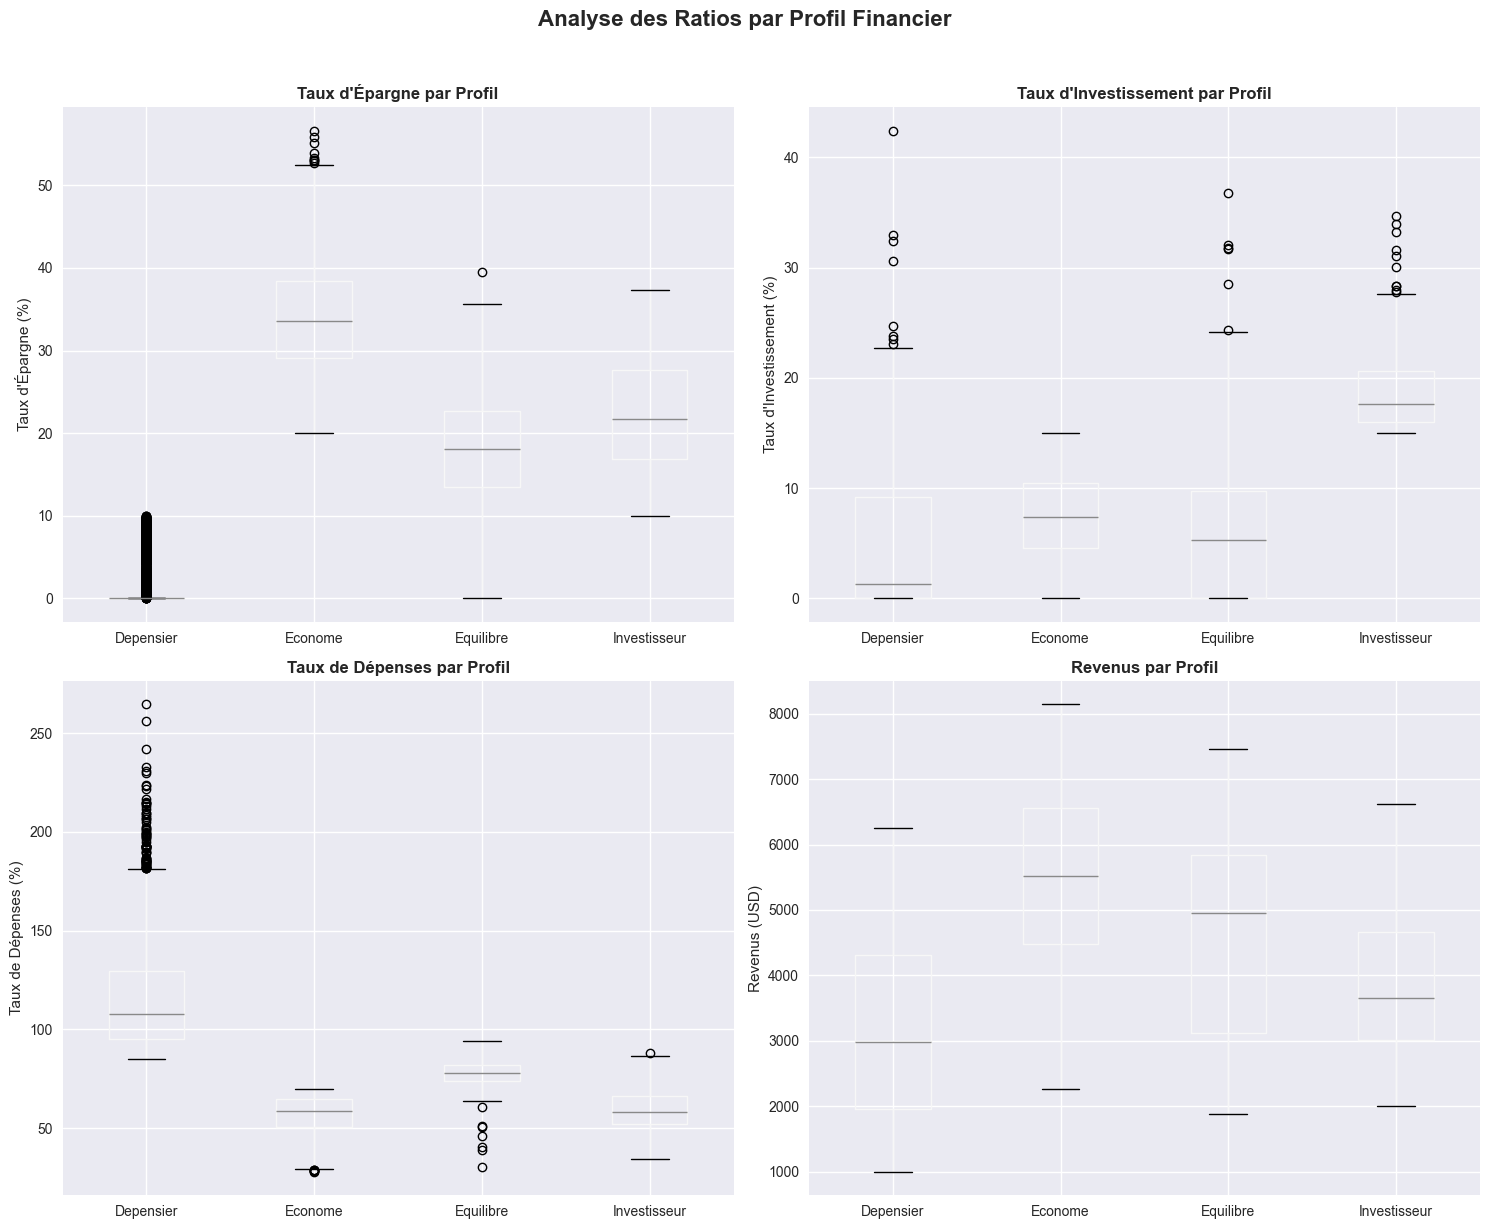

In [6]:
# Analyse des ratios par profil financier
print("📊 Statistiques des ratios par profil financier:")
print("=" * 70)

profile_stats = df_features.groupby('Financial_Profile').agg({
    'Savings_Rate': ['mean', 'median', 'std'],
    'Investment_Rate': ['mean', 'median', 'std'],
    'Expense_Rate': ['mean', 'median', 'std'],
    'Income (USD)': ['mean', 'median']
}).round(2)

print(profile_stats)

# Visualisation des ratios par profil
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Savings Rate
df_features.boxplot(column='Savings_Rate', by='Financial_Profile', ax=axes[0, 0])
axes[0, 0].set_title('Taux d\'Épargne par Profil', fontweight='bold')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Taux d\'Épargne (%)')

# Investment Rate
df_features.boxplot(column='Investment_Rate', by='Financial_Profile', ax=axes[0, 1])
axes[0, 1].set_title('Taux d\'Investissement par Profil', fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Taux d\'Investissement (%)')

# Expense Rate
df_features.boxplot(column='Expense_Rate', by='Financial_Profile', ax=axes[1, 0])
axes[1, 0].set_title('Taux de Dépenses par Profil', fontweight='bold')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('Taux de Dépenses (%)')

# Income
df_features.boxplot(column='Income (USD)', by='Financial_Profile', ax=axes[1, 1])
axes[1, 1].set_title('Revenus par Profil', fontweight='bold')
axes[1, 1].set_xlabel('')
axes[1, 1].set_ylabel('Revenus (USD)')

plt.suptitle('Analyse des Ratios par Profil Financier', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../data/results/ratios_by_profile.png', dpi=300, bbox_inches='tight')
plt.show()


## 6. Sauvegarde des Données avec Features

**⚠️ IMPORTANT**: Nous sauvegardons les données avec toutes les features, mais pour l'ACP et le clustering,
nous utiliserons UNIQUEMENT les variables originales (sans les ratios et sans le target).


In [7]:
# Sauvegarde des données avec toutes les features
df_features.to_csv('../data/processed/dataset_with_features.csv', index=False)

# Identification des colonnes pour l'analyse
# Variables originales (à utiliser pour ACP et Clustering)
original_vars = [
    'Age', 'Income (USD)', 'Rent (USD)', 'Groceries (USD)', 
    'Eating Out (USD)', 'Entertainment (USD)', 'Subscription Services (USD)',
    'Education (USD)', 'Online Shopping (USD)', 'Savings (USD)', 
    'Investments (USD)', 'Travel (USD)', 'Fitness (USD)', 'Miscellaneous (USD)'
]

# Variables dérivées (ratios et indices - NE PAS utiliser dans ACP/Clustering)
derived_vars = [
    'Savings_Rate', 'Investment_Rate', 'Expense_Rate', 
    'Total_Expenses', 'Disposable_Income',
    'Lifestyle_Index', 'Education_Index', 'Health_Index', 'Digital_Index'
]

# Variables catégorielles
categorical_vars = ['Income_Category', 'Financial_Profile']

# Sauvegarde des métadonnées
feature_engineering_summary = {
    'original_variables': original_vars,
    'derived_variables': derived_vars,
    'categorical_variables': categorical_vars,
    'target_variable': 'Financial_Profile',
    'note': 'Les ratios et indices NE DOIVENT PAS être utilisés dans ACP et Clustering car ils biaisent les résultats',
    'profile_distribution': df_features['Financial_Profile'].value_counts().to_dict(),
    'savings_rate_mean': float(df_features['Savings_Rate'].mean()),
    'investment_rate_mean': float(df_features['Investment_Rate'].mean()),
    'lifestyle_index_mean': float(df_features['Lifestyle_Index'].mean())
}

with open('../data/results/feature_engineering_summary.json', 'w', encoding='utf-8') as f:
    json.dump(feature_engineering_summary, f, indent=2, ensure_ascii=False)

print("✅ Données avec features sauvegardées!")
print(f"📁 Fichier: data/processed/dataset_with_features.csv")
print(f"📁 Métadonnées: data/results/feature_engineering_summary.json")
print(f"\n📊 Résumé:")
print(f"   - Variables originales: {len(original_vars)}")
print(f"   - Variables dérivées (ratios/indices): {len(derived_vars)}")
print(f"   - Variables catégorielles: {len(categorical_vars)}")
print(f"   - Target: Financial_Profile")
print(f"\n⚠️ RAPPEL: Pour ACP et Clustering, utiliser UNIQUEMENT les variables originales!")


✅ Données avec features sauvegardées!
📁 Fichier: data/processed/dataset_with_features.csv
📁 Métadonnées: data/results/feature_engineering_summary.json

📊 Résumé:
   - Variables originales: 14
   - Variables dérivées (ratios/indices): 9
   - Variables catégorielles: 2
   - Target: Financial_Profile

⚠️ RAPPEL: Pour ACP et Clustering, utiliser UNIQUEMENT les variables originales!
